# Effective kernel 확인

학습된 Mamba 모델에 validation window 몇 개를 넣고, `effective_kernels()`의 출력 tensor와 일부 행렬을 확인합니다.
먼저 `data/har`를 받아 두어야 합니다 (README의 "데이터 받기").

In [1]:
import sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent                      # 이 notebook은 effective_kernel/ 안에서 실행
sys.path[:0] = [str(ROOT / "mamba_starter"), str(ROOT / "effective_kernel")]
from evaluate import load_checkpoint, evaluation_data
from data import HAR_CLASSES
from effective_kernel import effective_kernels

MODEL, SEED = "mamba_selective", 0            # mamba_selective / mamba_lti, seed 0 / 1 / 2
device = "cuda" if torch.cuda.is_available() else "cpu"


## 모델과 입력
class마다 validation window 1개씩, 총 6개를 넣습니다.

In [2]:
model, ckpt = load_checkpoint(ROOT / "checkpoints" / MODEL / f"seed_{SEED}" / "best.pt", device)
x, y = evaluation_data(ckpt, data_root=str(ROOT / "data" / "har"))   # 정규화된 validation 입력
idx = [int((y == k).nonzero()[0][0]) for k in range(6)]
xb = torch.as_tensor(x[idx], device=device)
xb.shape

torch.Size([6, 128, 9])

## Effective kernel 계산
`K`는 (sample, layer, channel, i, j) 모양이고, 인덱싱할 때 행렬을 계산합니다.

In [3]:
logits, K = effective_kernels(model, xb)
print("K.shape   :", K.shape)
print("K[0,0,0]  :", tuple(K[0, 0, 0].shape), K[0, 0, 0].dtype)
print("label     :", [HAR_CLASSES[k] for k in y[idx]])
print("predicted :", [HAR_CLASSES[k] for k in logits.argmax(-1).tolist()])

K.shape   : (6, 2, 64, 128, 128)
K[0,0,0]  : (128, 128) torch.float64
label     : ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
predicted : ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']


In [4]:
K[0, 0, 0][:5, :5]    # 왼쪽 위 5x5: 위쪽 삼각형은 0 (인과성), 대각선에는 D가 더해져 있음

tensor([[1.1917, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1402, 1.3307, 0.0000, 0.0000, 0.0000],
        [0.1424, 0.2777, 1.4897, 0.0000, 0.0000],
        [0.1681, 0.3261, 0.5017, 1.6395, 0.0000],
        [0.1514, 0.2924, 0.4468, 0.5160, 1.6937]], dtype=torch.float64)

## 행렬 시각화
layer 0, channel 0의 행렬을 class별로 그립니다. 행 i는 출력 시점, 열 j는 입력 시점입니다.
대각선(D ≈ 1)이 다른 값보다 훨씬 커서, 색 범위는 대각선을 뺀 값으로 맞췄습니다.

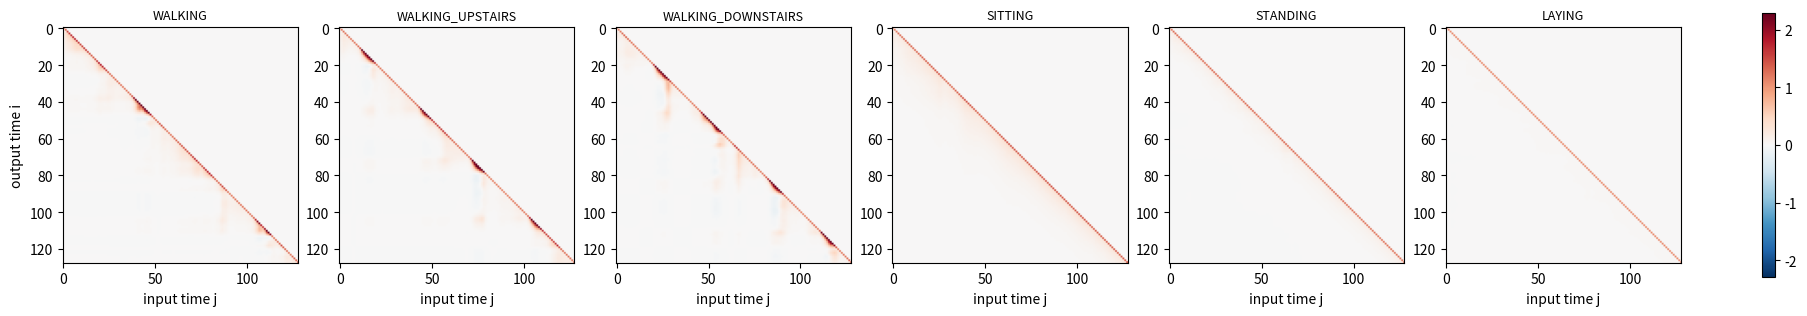

In [5]:
layer, ch = 0, 0
M = K[:, layer, ch]                                   # [6, 128, 128]
off = M - torch.diag_embed(torch.diagonal(M, dim1=1, dim2=2))
v = off.abs().max().item()
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4), constrained_layout=True)
for s, ax in enumerate(axes):
    im = ax.imshow(M[s], cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(HAR_CLASSES[y[idx[s]]], fontsize=9)
    ax.set_xlabel("input time j")
axes[0].set_ylabel("output time i")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

마지막 출력 시점(i = 127)의 행, 즉 과거 입력 j가 마지막 출력에 주는 가중치입니다 (j = 127은 D가 더해진 값이라 제외).

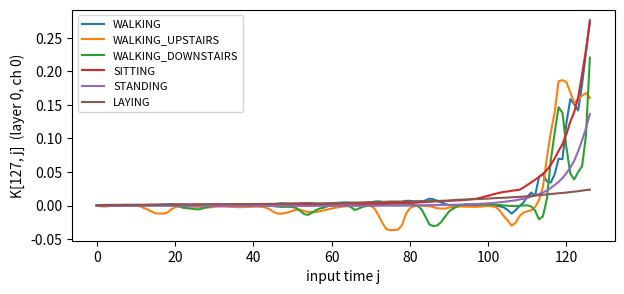

In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
for s in range(6):
    ax.plot(M[s, -1, :-1], lw=1.5, label=HAR_CLASSES[y[idx[s]]])
ax.set_xlabel("input time j"); ax.set_ylabel(f"K[127, j]  (layer {layer}, ch {ch})")
ax.legend(fontsize=8); plt.show()